# Unidad III Regresión de peso

Este experimento predice `Weight` con filas procesadas y validadas por Unidad II. Las filas completas exactamente duplicadas permanecen en un mismo grupo, tanto en la partición final como en validación cruzada. Las transformaciones aprendidas se ajustan dentro de pipelines en cada fold y sólo con entrenamiento. `NObeyesdad` se excluye como predictor. El test queda reservado para la evaluación final.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from src.unit_iii.data import validate_input, split_indices, split_summary
from src.unit_iii.regression import run_regression
ROOT = Path.cwd()
frame, u2_manifest = validate_input(ROOT)
train_idx, test_idx, groups = split_indices(frame)
split_summary(frame, train_idx, test_idx, groups)

{'random_state': 42,
 'splitter': 'StratifiedGroupKFold(n_splits=5, shuffle=True); first fold reserved as final test',
 'train_indices': [0,
  1,
  2,
  4,
  5,
  7,
  8,
  10,
  11,
  12,
  13,
  15,
  16,
  18,
  20,
  21,
  22,
  24,
  25,
  26,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  46,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  58,
  59,
  60,
  61,
  62,
  63,
  64,
  65,
  66,
  67,
  68,
  69,
  70,
  71,
  73,
  74,
  75,
  76,
  77,
  78,
  79,
  81,
  82,
  83,
  85,
  86,
  87,
  88,
  89,
  90,
  91,
  92,
  93,
  94,
  95,
  96,
  97,
  98,
  99,
  100,
  101,
  102,
  103,
  104,
  107,
  108,
  109,
  110,
  111,
  113,
  114,
  116,
  117,
  120,
  121,
  122,
  124,
  125,
  126,
  127,
  128,
  129,
  131,
  132,
  133,
  134,
  135,
  137,
  139,
  140,
  142,
  143,
  144,
  146,
  147,
  149,
  151,
  152,
  153,
  154,
  155,
  156,
  157,
  158,
  159,
  162,
  163,
  165,
  166,
  167,
  168,
  1

## Modelos base y evaluación
DummyRegressor establece la referencia; LinearRegression y RandomForestRegressor se comparan mediante GroupKFold de entrenamiento y el test reservado. R², MAE y RMSE son métricas descriptivas de esta muestra.

,model,train_mae,train_rmse,train_r2,test_mae,test_rmse,test_r2,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std,train_test_rmse_gap
0,DummyRegressor_mean,21.8953,26.2768,0.0000,21.9245,25.8146,-0.0001,21.9032,0.2675,26.2825,0.3216,-0.0016,0.0020,-0.4622
1,LinearRegression,13.4841,16.9882,0.5820,13.4350,16.6931,0.5818,13.6739,0.5874,17.2341,0.6279,0.5692,0.0244,-0.2951
2,RandomForestRegressor,1.8077,3.1548,0.9856,4.7501,8.1428,0.9005,5.3825,0.3903,8.9627,1.0288,0.8826,0.0251,4.9880


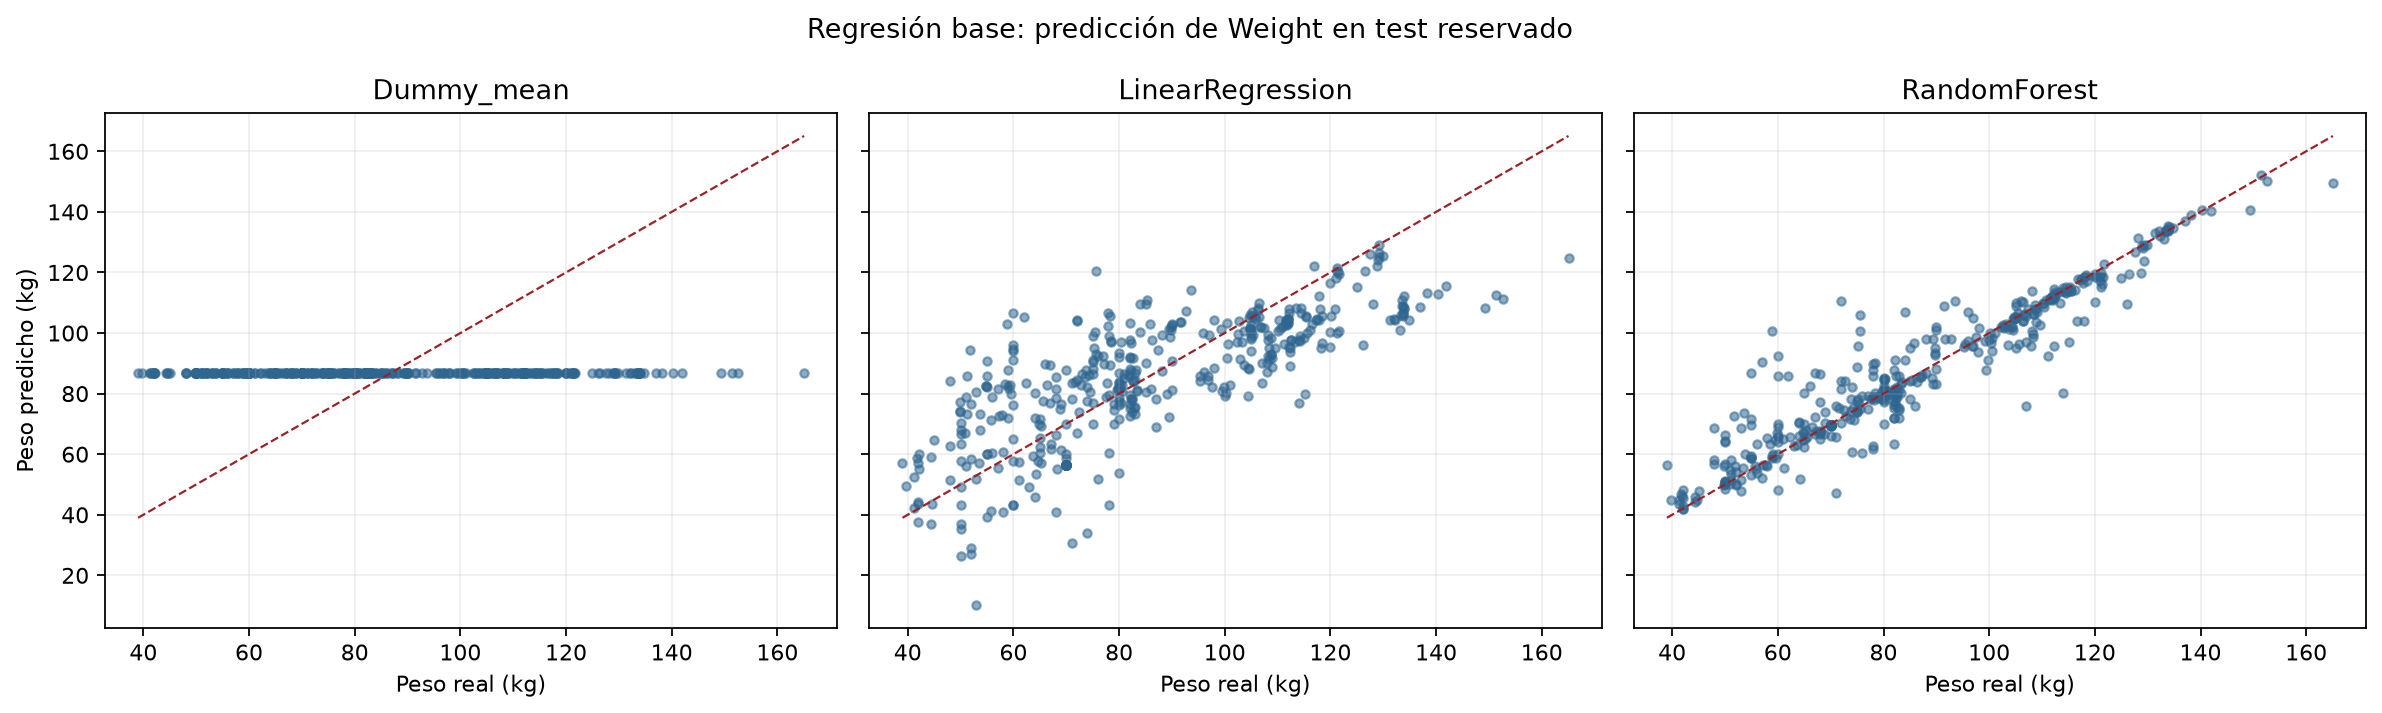

In [2]:
regression_results = run_regression(ROOT)
display(regression_results['metrics'].round(4))
display(Image(filename=str(regression_results['figure_path'])))